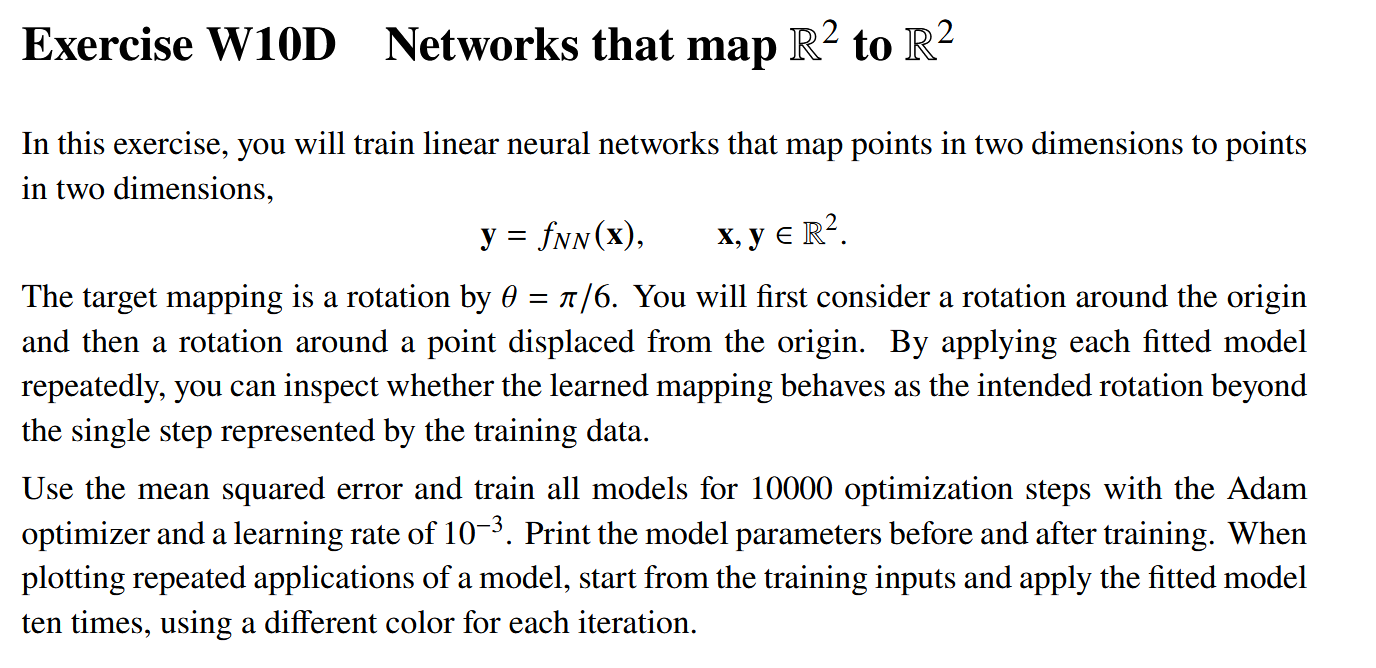
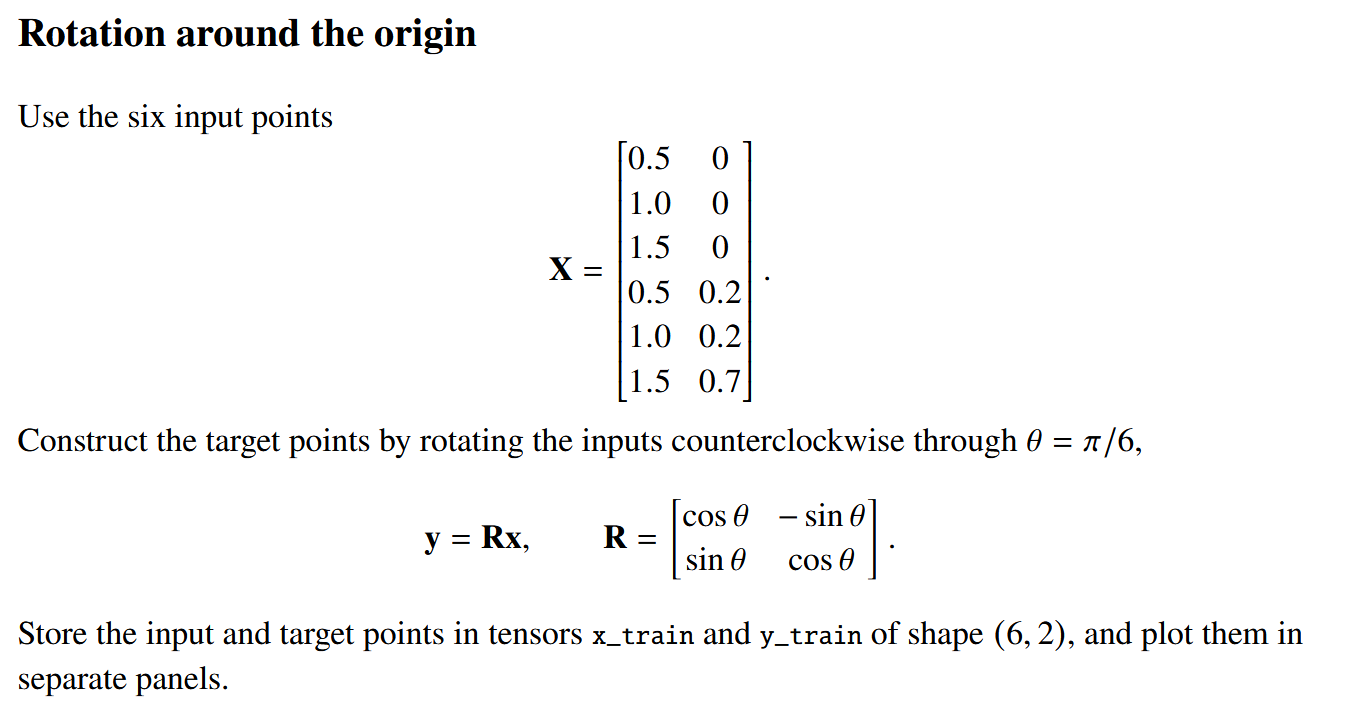


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from models import *

class XDLinearModel(nn.Module):
    def __init__(self, dim, hidden=None, layers=0, bias=True, *args, **kwargs):
        super().__init__(*args, **kwargs)
        
        self.dim = dim
        self.hidden = hidden if hidden is not None else dim
        self.is_fitted = False
        
        self.net = nn.ModuleList()
        
        if layers == 0:
            self.net.append(nn.Linear(self.dim, self.dim, bias=bias))
        else:
            self.net.append(nn.Linear(self.dim, self.hidden, bias=bias))
            
            for _ in range(layers - 1):
                self.net.append(nn.Linear(self.hidden, self.hidden, bias=bias))
                
            self.net.append(nn.Linear(self.hidden, self.dim, bias=bias))

    def forward(self, x):
        x = x.view(-1, self.dim)
        for layer in self.net:
            x = layer(x)
            
        if self.dim == 1:
            return x.flatten()
        return x

    def fit(self, xs, ys, epochs=500, lr=0.1, lossFunction=nn.MSELoss, optimizerFunc=optim.Adam):
        self.lossFunc = lossFunction()
        self.optimizer = optimizerFunc(self.parameters(), lr=lr)

        for _ in range(epochs):
            self.optimizer.zero_grad()
            pred = self(xs)
            loss = self.lossFunc(pred, ys)
            loss.backward()
            self.optimizer.step()

        self.is_fitted = True
        return tuple(self.parameters())

def rotation_plot(ax, model, x_train, y_train):
    print("Parameters before training:")
    print(model.net[0].weight.data)

    model.fit(x_train, y_train, epochs=10000, lr=1e-3)

    print("\nParameters after training:")
    print(model.net[0].weight.data)

    ax.scatter(x_train[:, 0].numpy(), x_train[:, 1].numpy(), color='black', marker='x')

    current_points = x_train
    colors = plt.cm.viridis(torch.linspace(0, 1, 10).numpy())

    with torch.no_grad():
        for i in range(10):
            current_points = model(current_points)
            ax.scatter(
                current_points[:, 0].numpy(), 
                current_points[:, 1].numpy(), 
                color=colors[i]
            )

    ax.set_title('Repeated Applications (10 Steps)')
    ax.set_aspect('equal')
    ax.grid(True)


theta = np.pi / 6

x_train = torch.tensor([
    [0.5, 0.0],
    [1.0, 0.0],
    [1.5, 0.0],
    [0.5, 0.2],
    [1.0, 0.2],
    [1.5, 0.7]
], dtype=torch.float32)

R = torch.tensor([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
], dtype=torch.float32)

y_train = x_train @ R.T

print(f'R = ')
print(R)

R = 
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


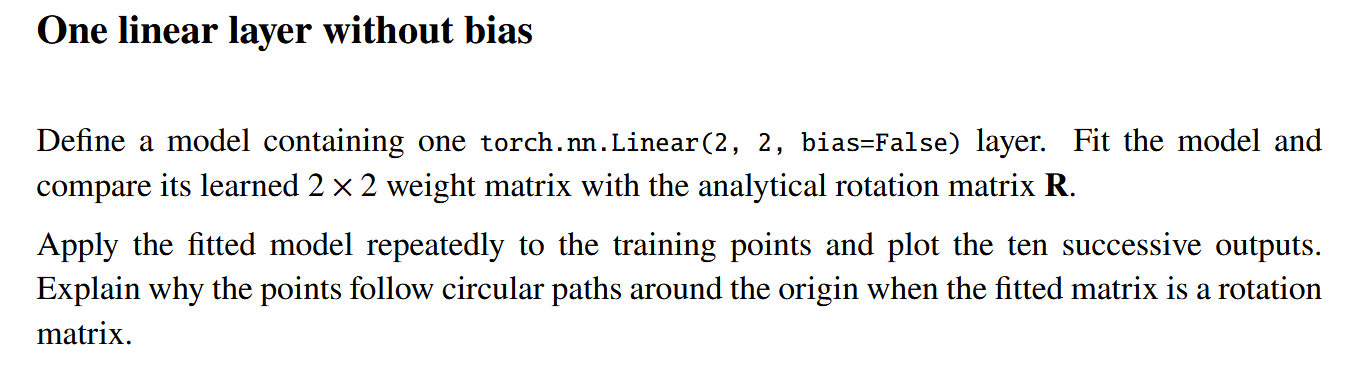

Parameters before training:
tensor([[ 0.4701,  0.4395],
        [-0.4433, -0.1858]])

Parameters after training:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


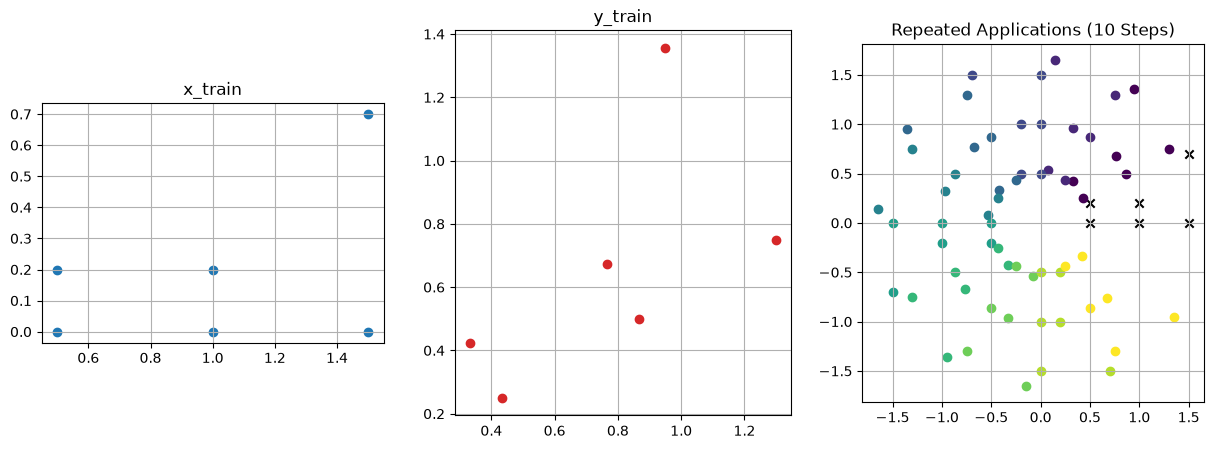

In [24]:
model = XDLinearModel(dim=2, layers=0, bias=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(x_train[:, 0].numpy(), x_train[:, 1].numpy(), color='tab:blue')
axes[0].set_title('x_train')
axes[0].set_aspect('equal')
axes[0].grid(True)

axes[1].scatter(y_train[:, 0].numpy(), y_train[:, 1].numpy(), color='tab:red')
axes[1].set_title('y_train')
axes[1].set_aspect('equal')
axes[1].grid(True)

rotation_plot(axes[2], model, x_train, y_train)

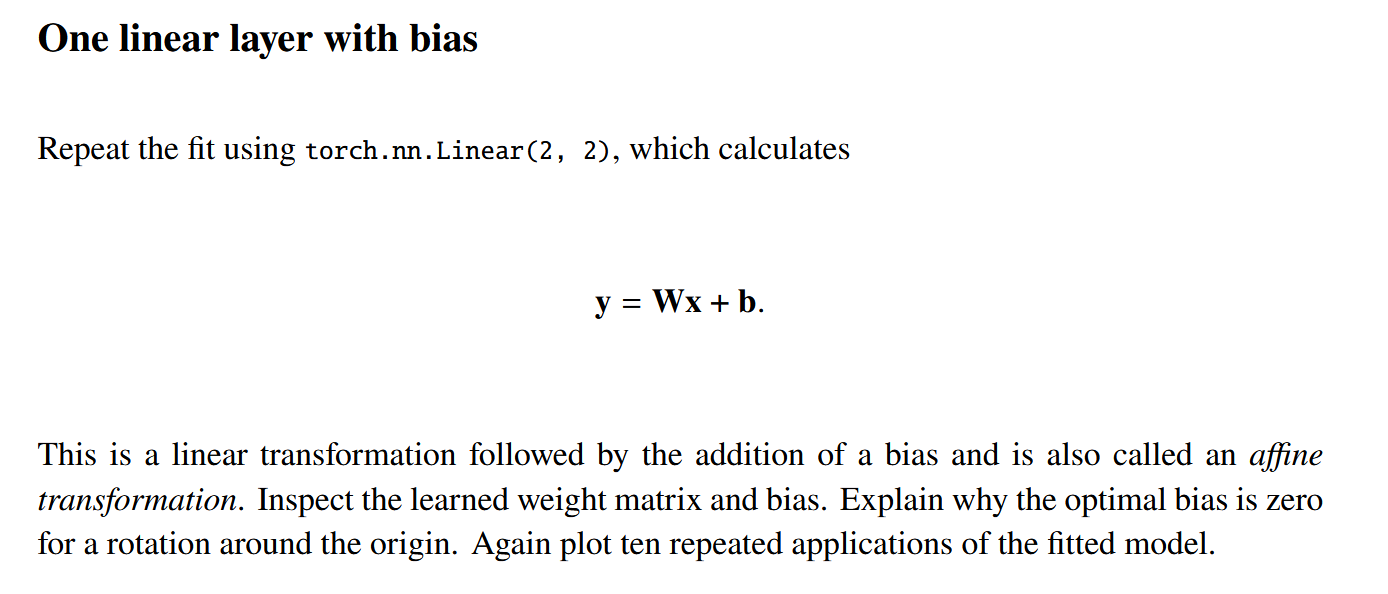

Parameters before training:
tensor([[ 0.2224, -0.6919],
        [-0.0090,  0.0554]])

Parameters after training:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


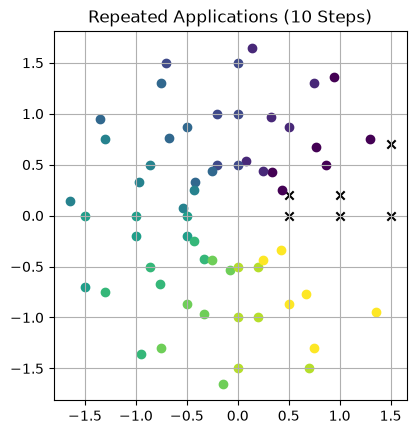

In [25]:
model = XDLinearModel(2)

fig, ax = plt.subplots()
rotation_plot(ax, model, x_train, y_train)

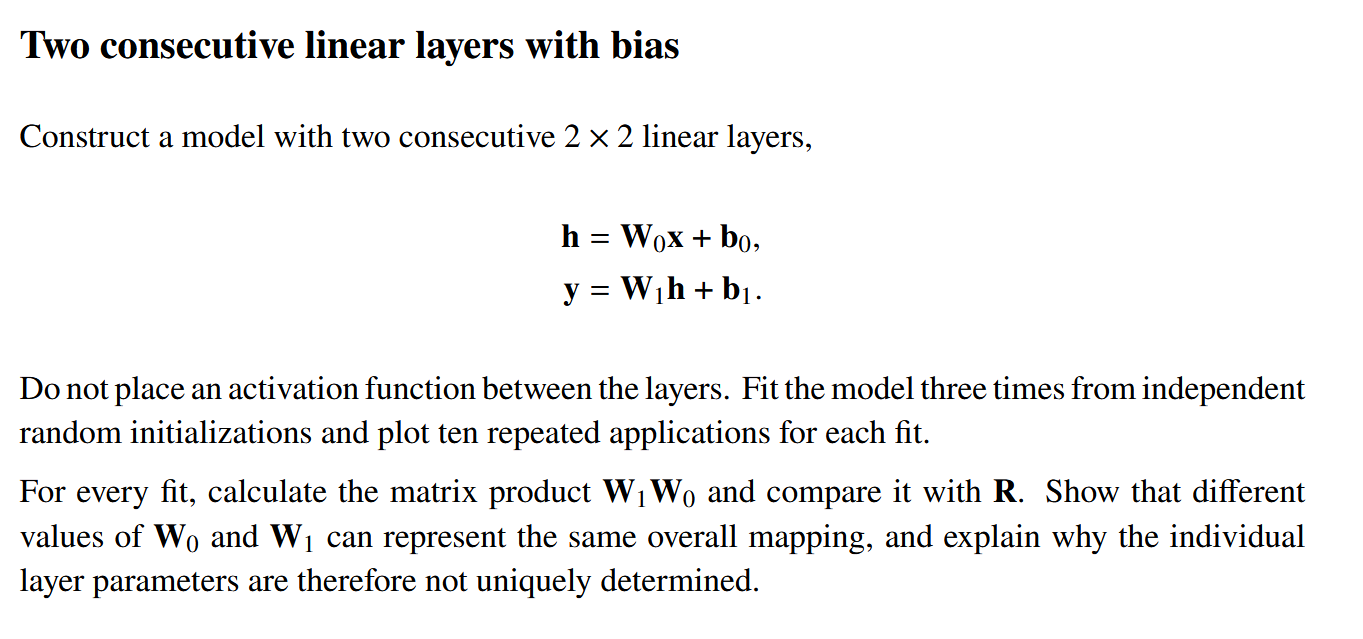

--- Fit 1 ---
W0:
tensor([[-0.8613, -0.1470],
        [ 0.0403,  1.1054]])
W1:
tensor([[-1.0332, -0.5897],
        [-0.5473,  0.7107]])
W1 @ W0:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])

--- Fit 2 ---
W0:
tensor([[ 0.9001,  0.0872],
        [-0.4677,  1.1499]])
W1:
tensor([[ 0.7084, -0.4885],
        [ 0.9109,  0.6840]])
W1 @ W0:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])

--- Fit 3 ---
W0:
tensor([[-0.0665,  1.0740],
        [-0.7816,  0.0285]])
W1:
tensor([[-0.4371, -1.0708],
        [ 0.8252, -0.7099]])
W1 @ W0:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])

--- Target Rotation Matrix R ---
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])


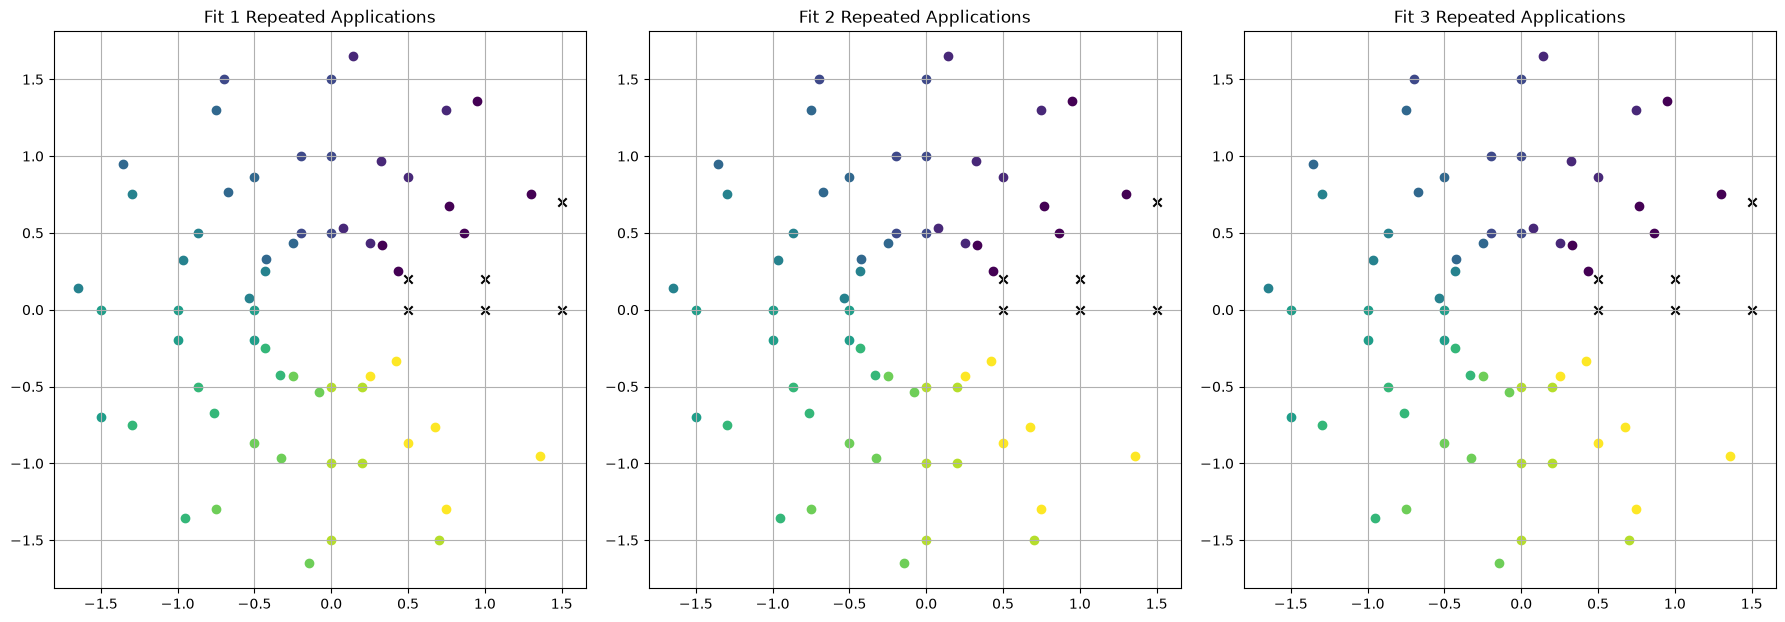

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.viridis(torch.linspace(0, 1, 10).numpy())

for i in range(3):
    model = XDLinearModel(dim=2, layers=1, bias=True)
    
    model.fit(x_train, y_train, epochs=10000, lr=1e-3)
    
    W0 = model.net[0].weight.data
    W1 = model.net[1].weight.data
    
    W1_W0 = W1 @ W0
    
    print(f"--- Fit {i+1} ---")
    print(f"W0:\n{W0}")
    print(f"W1:\n{W1}")
    print(f"W1 @ W0:\n{W1_W0}\n")
    
    current_points = x_train
    axes[i].scatter(x_train[:, 0].numpy(), x_train[:, 1].numpy(), color='black', marker='x')
    
    with torch.no_grad():
        for step in range(10):
            current_points = model(current_points)
            axes[i].scatter(
                current_points[:, 0].numpy(), 
                current_points[:, 1].numpy(), 
                color=colors[step]
            )
            
    axes[i].set_title(f'Fit {i+1} Repeated Applications')
    axes[i].set_aspect('equal')
    axes[i].grid(True)

print("--- Target Rotation Matrix R ---")
print(R)

plt.tight_layout()
plt.show()

### **Explanation**
When you run this, you will notice that the individual matrices $\mathbf{W}_0$ and $\mathbf{W}_1$ are completely different across the three independent random initializations. However, the matrix product $\mathbf{W}_1\mathbf{W}_0$ will always perfectly match the target rotation matrix $\mathbf{R}$. Furthermore, all three plots of the repeated applications will show identical, clean rotational behavior.

The individual layer parameters are not uniquely determined because there is no non-linear activation function between the layers. As a result, the two consecutive linear operations collapse algebraically into a single affine transformation:

$\mathbf{y} = \mathbf{W}_1(\mathbf{W}_0\mathbf{x} + \mathbf{b}_0) + \mathbf{b}_1 = (\mathbf{W}_1\mathbf{W}_0)\mathbf{x} + (\mathbf{W}_1\mathbf{b}_0 + \mathbf{b}_1)$

The neural network only needs the final effective matrix $(\mathbf{W}_1\mathbf{W}_0)$ to equal $\mathbf{R}$. Mathematically, for any invertible $2 \times 2$ matrix $\mathbf{M}$, you could rewrite this relationship as $\mathbf{W}_1\mathbf{M}^{-1}\mathbf{M}\mathbf{W}_0$. This means there are infinitely many combinations of $\mathbf{W}_0$ and $\mathbf{W}_1$ that will multiply together to produce the exact same overall mapping.

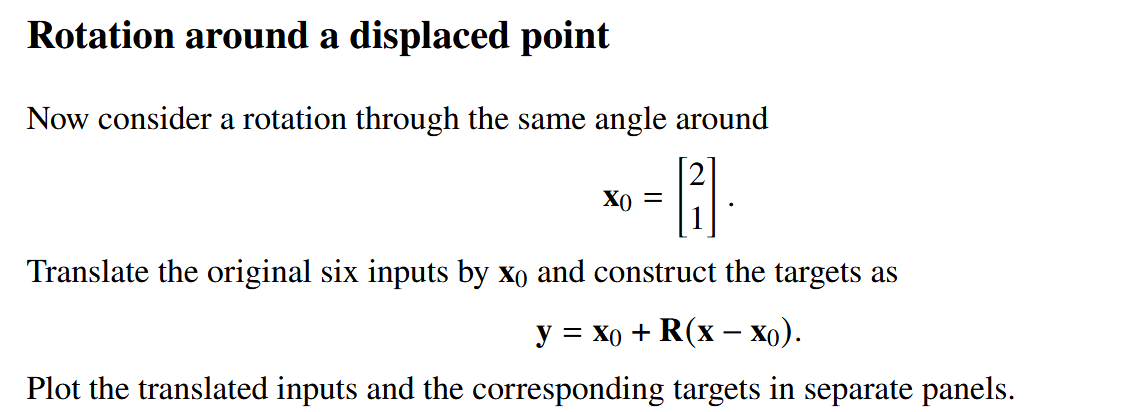

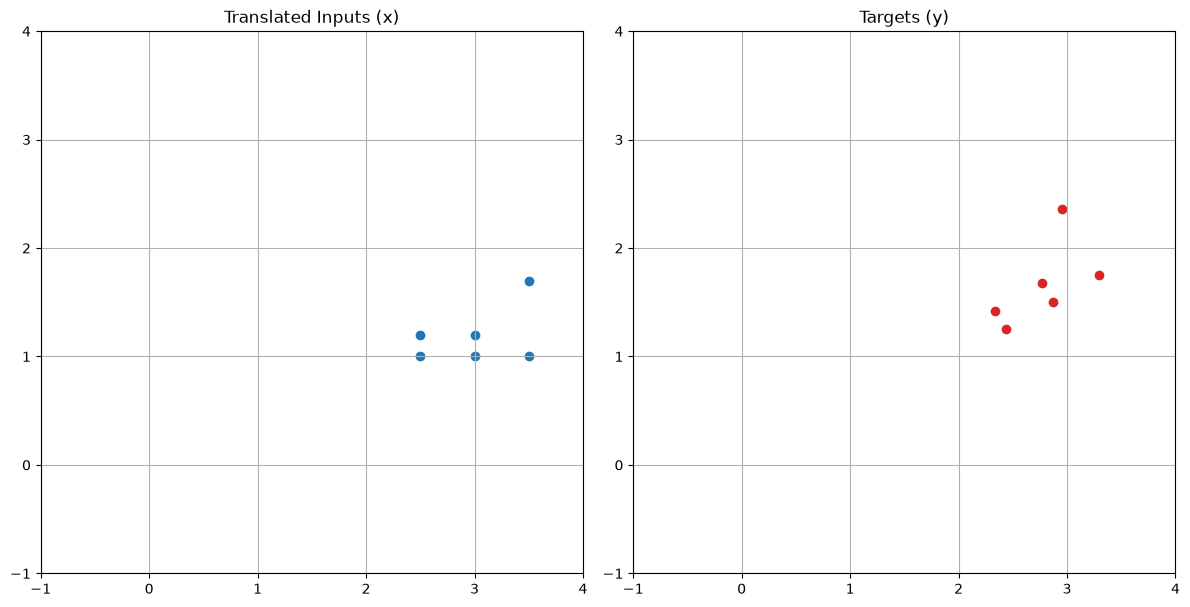

In [27]:
x0 = torch.tensor([2.0, 1.0], dtype=torch.float32)

x_train_disp = x_train + x0

y_train_disp = (x_train_disp - x0) @ R.T + x0

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].scatter(x_train_disp[:, 0].numpy(), x_train_disp[:, 1].numpy(), color='tab:blue')
axes[0].set_title('Translated Inputs (x)')
axes[0].set_aspect('equal')
axes[0].set_xlim(-1,4)
axes[0].set_ylim(-1,4)
axes[0].grid(True)

axes[1].scatter(y_train_disp[:, 0].numpy(), y_train_disp[:, 1].numpy(), color='tab:red')
axes[1].set_title('Targets (y)')
axes[1].set_aspect('equal')
axes[1].set_xlim(-1,4)
axes[1].set_ylim(-1,4)
axes[1].grid(True)

plt.tight_layout()
plt.show()

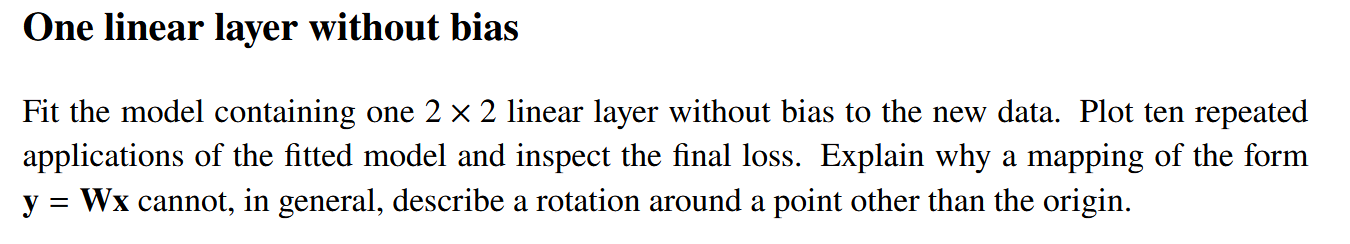
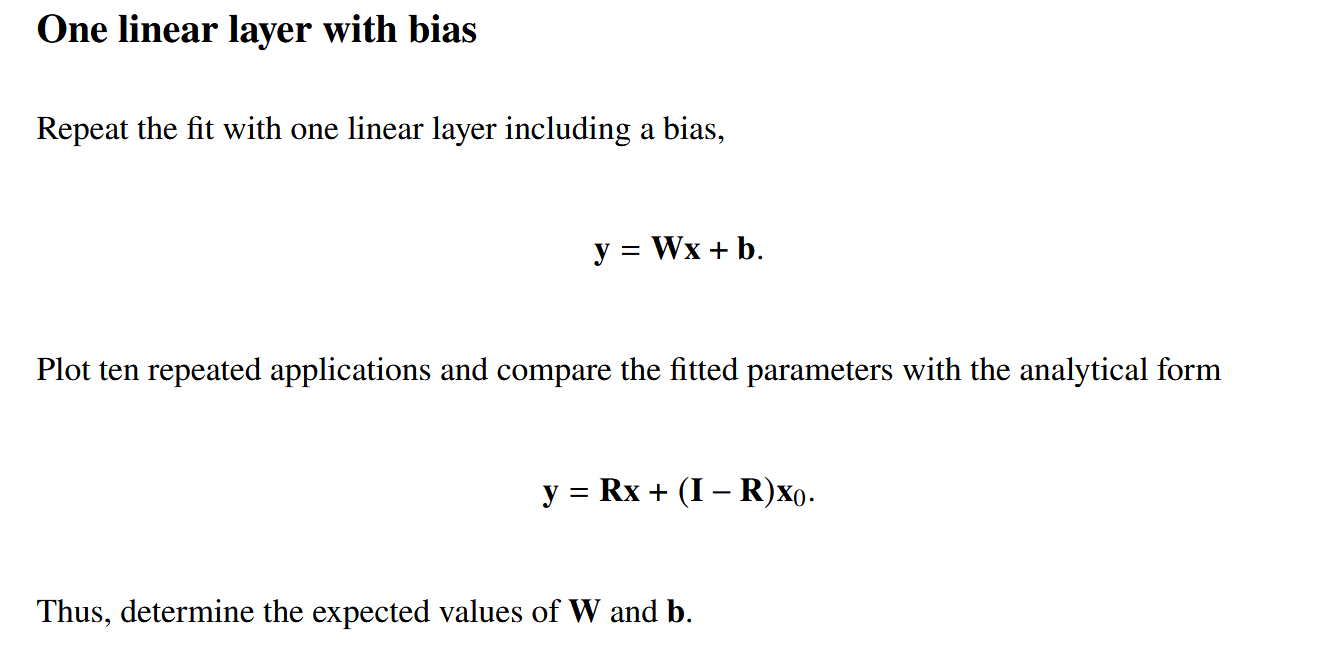

Parameters before training:
tensor([[ 0.4558, -0.1105],
        [-0.6953, -0.4250]])

Parameters after training:
tensor([[ 1.0738, -0.3887],
        [ 0.2691,  0.7321]])

Parameters before training:
tensor([[ 0.0835,  0.6882],
        [-0.2235,  0.1087]])

Parameters after training:
tensor([[ 0.8692, -0.4989],
        [ 0.4861,  0.8619]])


(-1.0, 4.0)

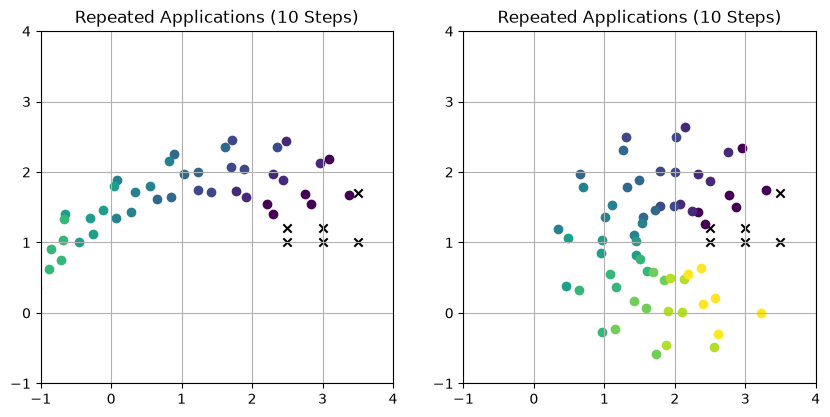

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

model1 = XDLinearModel(2, bias=False)
rotation_plot(ax1, model1, x_train_disp, y_train_disp)
ax1.set_xlim(-1,4)
ax1.set_ylim(-1,4)
print('')

model2 = XDLinearModel(2, bias=True)
rotation_plot(ax2, model2, x_train_disp, y_train_disp)
ax2.set_xlim(-1,4)
ax2.set_ylim(-1,4)

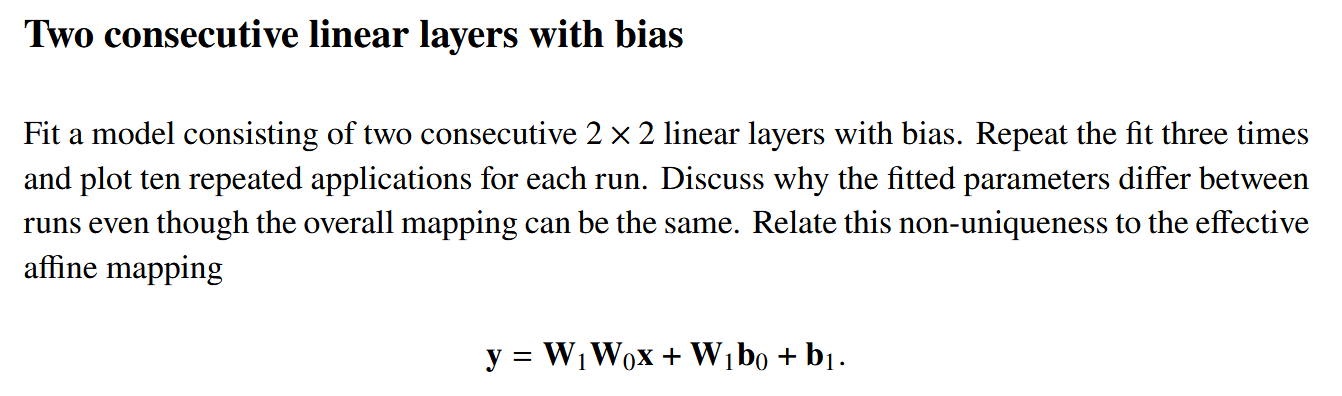
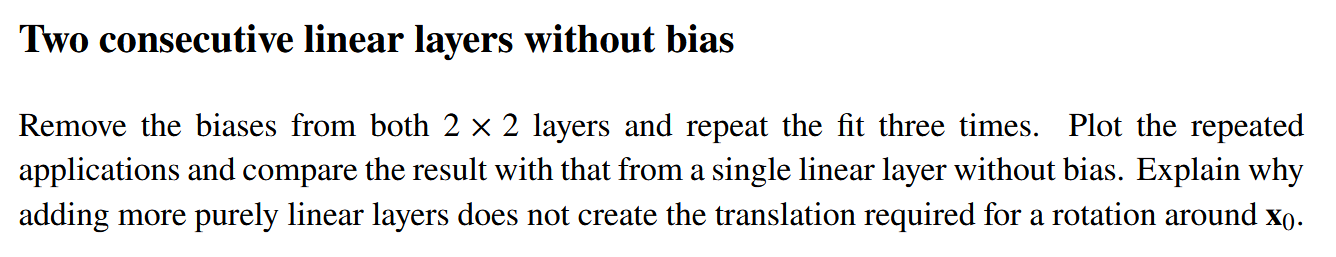

--- Model No Bias ---
W0:
tensor([[-1.5227, -0.0191],
        [-0.0517, -1.2109]])
W1:
tensor([[-0.7165,  0.3324],
        [-0.1539, -0.6091]])
W1 @ W0:
tensor([[ 1.0738, -0.3887],
        [ 0.2658,  0.7405]])

--- Model Bias ---
W0:
tensor([[ 0.3316, -0.5881],
        [ 0.7710,  0.1319]])
W1:
tensor([[ 1.0051,  0.6910],
        [-1.2104,  1.1690]])
W1 @ W0:
tensor([[ 0.8660, -0.5000],
        [ 0.5000,  0.8660]])



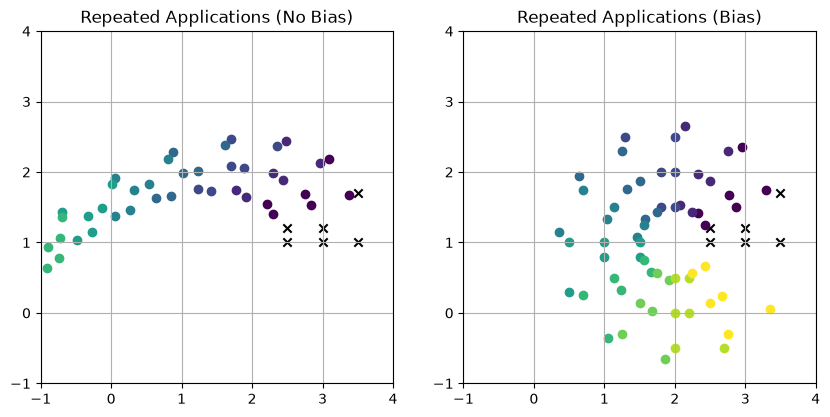

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

model1 = XDLinearModel(2, layers=1, bias=False)

model2 = XDLinearModel(2, layers=1, bias=True)


for ax, model, label in zip(axes, [model1, model2], ['No Bias', 'Bias']):
    
    model.fit(x_train_disp, y_train_disp, epochs=10000, lr=1e-3)
    
    W0 = model.net[0].weight.data
    W1 = model.net[1].weight.data
    
    W1_W0 = W1 @ W0
    
    print(f"--- Model {label} ---")
    print(f"W0:\n{W0}")
    print(f"W1:\n{W1}")
    print(f"W1 @ W0:\n{W1_W0}\n")
    
    current_points = x_train_disp
    ax.scatter(x_train_disp[:, 0].numpy(), x_train_disp[:, 1].numpy(), color='black', marker='x')
    
    with torch.no_grad():
        for step in range(10):
            current_points = model(current_points)
            ax.scatter(
                current_points[:, 0].numpy(), 
                current_points[:, 1].numpy(), 
                color=colors[step]
            )
            
    ax.set_title(f'Repeated Applications ({label})')
    ax.set_aspect('equal')
    ax.set_xlim(-1,4)
    ax.set_ylim(-1,4)
    ax.grid(True)

* **Two consecutive linear layers without bias:** A rotation around a displaced point $\mathbf{x}_0$ requires translating the space, which mathematically demands an additive constant. Adding more purely linear layers without bias only multiplies matrices together ($\mathbf{W}_n \dots \mathbf{W}_1 \mathbf{W}_0$), which simply results in another $2 \times 2$ matrix. A pure matrix multiplication always maps the origin to the origin. Therefore, no matter how many linear layers you stack, the network fundamentally cannot create the translation required to rotate around a point other than the origin. It will behave identically to a single linear layer without bias.


* **Two consecutive linear layers with bias:** When you fit two consecutive $2 \times 2$ linear layers with bias, the network learns the effective affine mapping $\mathbf{y} = \mathbf{W}_1\mathbf{W}_0\mathbf{x} + \mathbf{W}_1\mathbf{b}_0 + \mathbf{b}_1$. The fitted parameters ($\mathbf{W}_0, \mathbf{W}_1, \mathbf{b}_0, \mathbf{b}_1$) differ entirely between runs because they are non-unique. The network only requires the final combined product $\mathbf{W}_1\mathbf{W}_0$ to equal the target rotation matrix, and the final combined sum $\mathbf{W}_1\mathbf{b}_0 + \mathbf{b}_1$ to equal the required translation. An infinite combination of internal matrices and vectors can multiply and add together to achieve this exact same overall mapping.


* **A wider and deeper linear network:** A $2 \rightarrow 8 \rightarrow 8 \rightarrow 2$ network with biases but no activation functions contains many parameters, but it remains strictly an affine mapping. Because it is only a composition of linear layers and biases, the entire sequence of operations collapses mathematically into a single effective transformation of the form $\mathbf{y} = \mathbf{W}_{\text{eff}}\mathbf{x} + \mathbf{b}_{\text{eff}}$. Therefore, it is no more expressive than a single $2 \times 2$ linear layer with bias for this task. The internal parameters exhibit massive non-uniqueness because the network has vastly more degrees of freedom than constraints, allowing it to distribute the calculation across the intermediate $8$-dimensional layers in countless arbitrary ways while still converging to the exact same final $2 \times 2$ geometric output.